In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

# DOANH THU, SỐ CHƯƠNG TRÌNH KHUYẾN MÃI VÀ TỔNG LƯỢNG ĐƠN HÀNG QUA CÁC MỐC THỜI GIAN

# Lợi nhuận thu được

In [5]:
dfSale =  pd.read_csv("Analytical/sales.csv")
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     3833 non-null   object 
 1   Revenue  3833 non-null   float64
 2   COGS     3833 non-null   float64
dtypes: float64(2), object(1)
memory usage: 90.0+ KB


In [6]:
dfSale

,Date,Revenue,COGS
0,2012-07-04,5123547.94,3982991.19
1,2012-07-05,2751773.45,2150580.23
2,2012-07-06,3054029.42,2517632.84
3,2012-07-07,2667930.94,2108246.62
4,2012-07-08,2360851.90,1808622.79
...,...,...,...
3828,2022-12-27,2100553.66,2184872.24
3829,2022-12-28,3448729.20,3513621.00
3830,2022-12-29,3083944.33,3170787.10
3831,2022-12-30,2884668.76,3022292.15


In [7]:
dfSale.describe()

,Revenue,COGS
count,3.833000e+03,3.833000e+03
mean,4.286584e+06,3.695134e+06
std,2.624840e+06,2.219789e+06
min,2.798139e+05,2.365763e+05
25%,2.471089e+06,2.150580e+06
50%,3.647304e+06,3.161113e+06
75%,5.350877e+06,4.637294e+06
max,2.090527e+07,1.653586e+07


In [8]:
dfSale["Date"] = pd.to_datetime(dfSale["Date"])
# dfSale["yearMonth"] = dfSale["Date"].dt.strftime("%Y-%m")
dfSale["year"] = dfSale["Date"].dt.year
dfSale["month"] = dfSale["Date"].dt.month
dfSale["Revenue"] = dfSale["Revenue"]/100
dfSale["COGS"] = dfSale["COGS"]/100
dfSale["Profit"] = dfSale["Revenue"] - dfSale["COGS"]
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     3833 non-null   datetime64[ns]
 1   Revenue  3833 non-null   float64       
 2   COGS     3833 non-null   float64       
 3   year     3833 non-null   int32         
 4   month    3833 non-null   int32         
 5   Profit   3833 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int32(2)
memory usage: 149.9 KB


In [9]:
profitbyYear = dfSale.groupby(["year"])[["Profit"]].sum().reset_index().sort_values(by = ['year'])
profitbyYear[["year", "Profit"]]

,year,Profit
0,2012,1.540358e+06
1,2013,1.911893e+06
2,2014,2.972384e+06
3,2015,2.244920e+06
4,2016,3.240813e+06
5,2017,2.167785e+06
6,2018,3.079467e+06
7,2019,1.315986e+06
8,2020,1.684271e+06
9,2021,1.019097e+06


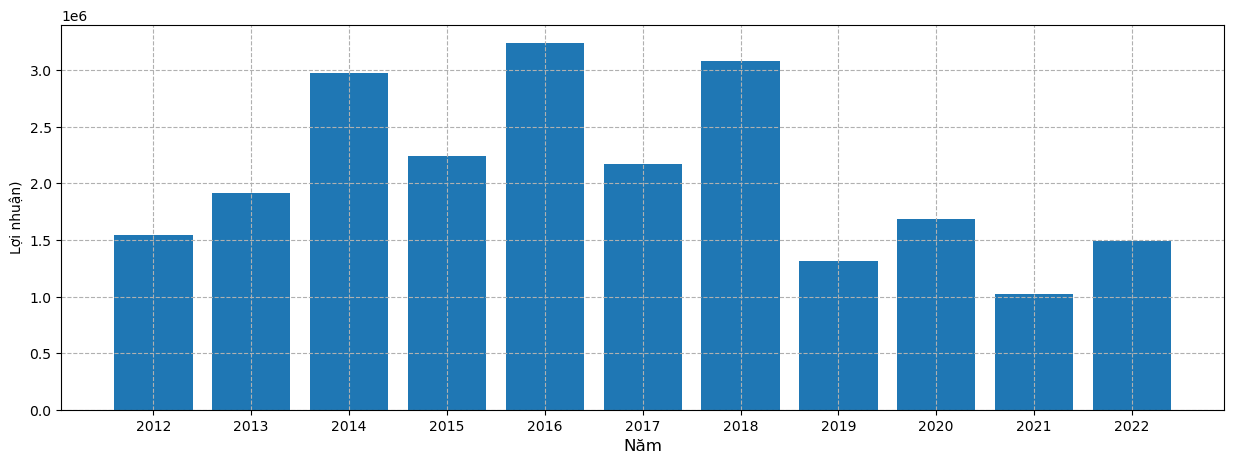

In [10]:
# profitbyYear = dfSale.groupby("year")["Profit"].sum()
# year = dfSale[]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    profitbyYear['year'],
    profitbyYear['Profit']
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(profitbyYear['year']),max(profitbyYear['year'])+1))
plt.show()

In [11]:
dfSales = dfSale.groupby(["year","month"])["Profit"].sum().reset_index()
pd.pivot_table(dfSales, values='Profit', index=['year'], columns=['month'], aggfunc='sum').fillna(0)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,278902.9964,335039.3388,267109.7900,221308.8942,203662.1783,234335.0444
2013,182848.7295,194962.6135,219368.7484,333449.7079,407409.5568,322150.6682,127007.4010,-356759.3504,113728.0815,224040.2237,132530.8104,11155.9502
2014,169867.8857,221770.0993,263432.5752,356831.1699,491156.3424,340256.7709,179078.8760,403062.6109,154494.1613,247009.2528,126064.9689,19359.5458
2015,179528.9384,216120.4669,259698.3562,420312.5076,492446.1980,376359.2147,154781.5022,-387716.2248,147764.8532,267832.8502,115127.7813,2663.6511
2016,210427.5078,249088.3802,249715.5281,398624.1797,528825.7842,406539.3688,186721.3918,450987.6096,160964.4461,252722.0019,137098.6841,9097.9662
2017,180839.3417,194501.2924,253488.0673,343351.3734,518406.4998,421671.8521,145843.6300,-415121.1125,111320.2214,270623.7152,133725.6373,9134.7993
2018,164411.6575,225087.2532,259909.2098,371310.7353,541847.2846,453279.6814,190640.8170,404388.4388,147044.2905,206881.6146,100836.5823,13829.3344
2019,144262.1581,160156.0476,174098.1740,213049.8358,296499.7231,224572.8588,75709.7710,-279003.4902,82267.2054,142695.7728,75080.8181,6596.7034
2020,97383.4415,126292.9683,164147.2080,221694.4940,272544.9514,180875.3030,93879.9963,240236.7929,87882.5209,137379.3648,57601.3598,4352.2107


In [12]:
revenuebyyearMonth =  dfSale.groupby(["year",'month'])[["Revenue", "COGS"]].sum().reset_index().sort_values(by = ['year', 'month'])
revenuebyyearMonth["Profit"] = revenuebyyearMonth["Revenue"] - revenuebyyearMonth["COGS"]
revenuebyyearMonth['date'] = pd.to_datetime(revenuebyyearMonth[['year', 'month']].assign(DAY=1))
revenuebyyearMonth = revenuebyyearMonth.sort_values('date')

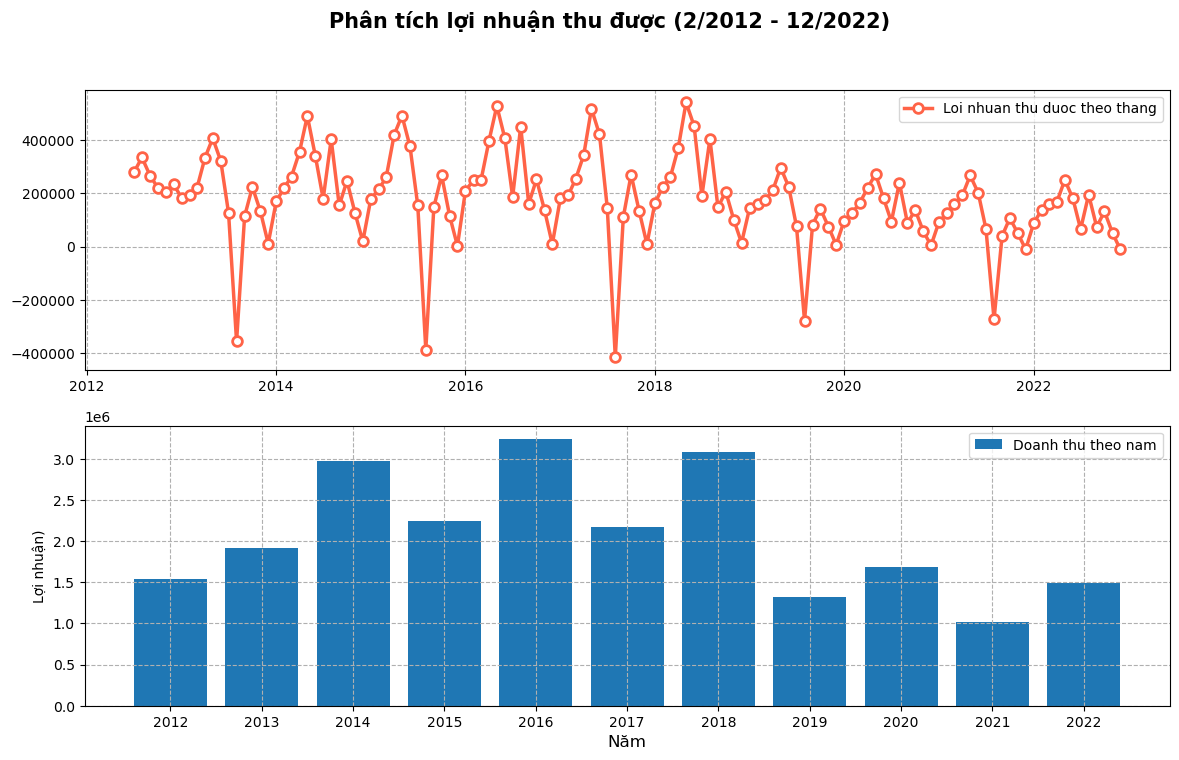

In [13]:
profitbyyearMonth = dfSale.groupby(["year",'month'])[["Profit"]].sum().reset_index().sort_values(by = ['year', 'month'])
profitbyyearMonth['date'] = pd.to_datetime(profitbyyearMonth[['year', 'month']].assign(DAY=1))
profitbyyearMonth = profitbyyearMonth.sort_values('date')



fig, axes = plt.subplots(2, 1, figsize=(14, 8))

fig.suptitle('Phân tích lợi nhuận thu được (2/2012 - 12/2022)',
             fontsize=15, fontweight='bold', y=0.98)


axes[0].plot(
    profitbyyearMonth['date'],
    profitbyyearMonth['Profit'],
    color='tomato',
    linewidth=2.5,
    marker='o',
    markersize=7,
    markerfacecolor='white',    # Tâm marker màu trắng
    markeredgewidth=2,          # Viền marker
    label='Loi nhuan thu duoc theo thang'
)
axes[0].grid(ls = "--")
axes[0].legend()


axes[1].bar(
    profitbyYear['year'],
    profitbyYear['Profit'],
    label = "Doanh thu theo nam"
)
axes[1].set_ylabel('Lợi nhuận)')
axes[1].set_xlabel('Năm', fontsize=12)
axes[1].grid(ls = "--")
axes[1].set_xticks(range(min(profitbyYear['year']),max(profitbyYear['year'])+1))
axes[1].legend()
plt.show()

In [94]:
profitbyyearMonth.iloc[99:]

,year,month,Profit,date
99,2020,10,137379.3648,2020-10-01
100,2020,11,57601.3598,2020-11-01
101,2020,12,4352.2107,2020-12-01
102,2021,1,93666.5346,2021-01-01
103,2021,2,125200.0030,2021-02-01
104,2021,3,160460.9462,2021-03-01
105,2021,4,193182.4684,2021-04-01
106,2021,5,267311.7020,2021-05-01
107,2021,6,201831.4950,2021-06-01
108,2021,7,65408.9435,2021-07-01


In [14]:
profitbyyearMonth[profitbyyearMonth["Profit"] <= 0].sort_values(by = ["Profit", "date"])

,year,month,Profit,date
61,2017,8,-415121.1125,2017-08-01
37,2015,8,-387716.2248,2015-08-01
13,2013,8,-356759.3504,2013-08-01
85,2019,8,-279003.4902,2019-08-01
109,2021,8,-273708.8938,2021-08-01
113,2021,12,-10439.9707,2021-12-01
125,2022,12,-10347.3724,2022-12-01


In [15]:
profitbyyearMonth[profitbyyearMonth["Profit"] <= 0]["year"].value_counts()

year
2021    2
2013    1
2015    1
2017    1
2019    1
2022    1
Name: count, dtype: int64

In [16]:
# Tap trung vao loi nhuan bi am tim hiem xem li do am la gi

In [17]:
# Lượng đơn hàng
dfOrder_item = pd.read_csv("Transaction/order_items.csv")
dfOrder = pd.read_csv("Transaction/orders.csv")
dfOrder_item.info()

C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_14828\278157817.py:2: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_item = pd.read_csv("Transaction/order_items.csv")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


In [18]:
# Số lượng đơn hàng
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder["year"] = dfOrder["order_date"].dt.year
dfOrder["month"] = dfOrder["order_date"].dt.month

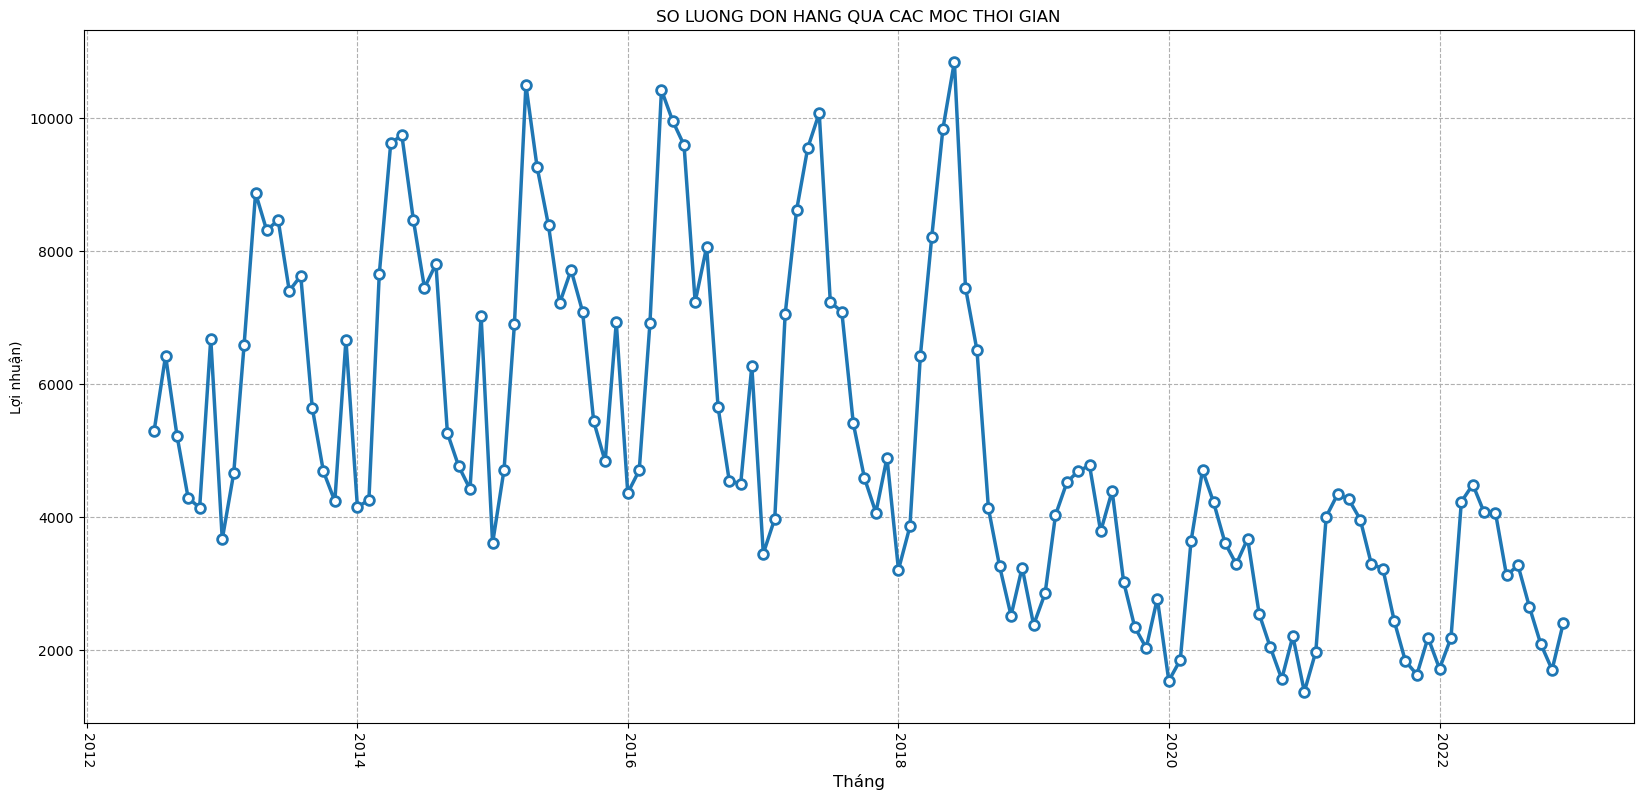

In [19]:
countOrder = dfOrder.groupby(["year",'month'])["order_id"].count().reset_index().sort_values(by = ['year', 'month']).rename(columns={"order_id": "count_order"})
countOrder['date'] = pd.to_datetime(countOrder[['year', 'month']].assign(DAY=1))
countOrder = countOrder.sort_values('date')



pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countOrder["date"],
    countOrder["count_order"],
    marker = "o",
    linewidth=2.5,
    markersize=7,
    markerfacecolor='white',    # Tâm marker màu trắng
    markeredgewidth=2,          # Viền marker
    label='So luong don hang'
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")
plt.title("SO LUONG DON HANG QUA CAC MOC THOI GIAN")
plt.show()

In [20]:
#Focus vao phan bi -profit la cac ngay thang trong kia
dateFocus = profitbyyearMonth[profitbyyearMonth["Profit"] <= 0].sort_values(by = ["date"]).rename(columns={"Profit": "FocusProfit"})
dateFocus =  pd.merge(dateFocus, countOrder[["count_order", "date"]], on = "date", how ="inner")
dateFocus = dateFocus.rename(columns={"count_order": "Focuscount_order"})
dateFocus = dateFocus.groupby("year")[["FocusProfit","Focuscount_order"]].sum()
totalOrderInYear =  dfOrder.groupby(["year"])["order_id"].count().reset_index().sort_values(by = ['year']).rename(columns={"order_id": "totalOrder"})
dateFocus = pd.merge(dateFocus, totalOrderInYear, on = "year", how ="inner")
dateFocus = pd.merge(dateFocus, profitbyYear, on = "year", how ="inner")

In [21]:
dateFocus

,year,FocusProfit,Focuscount_order,totalOrder,Profit
0,2013,-356759.3504,7630,76849,1.911893e+06
1,2015,-387716.2248,7717,82622,2.244920e+06
2,2017,-415121.1125,7091,76010,2.167785e+06
3,2019,-279003.4902,4391,41601,1.315986e+06
4,2021,-284148.8645,5411,34525,1.019097e+06
5,2022,-10347.3724,2400,36004,1.493287e+06


In [22]:
dateFocus["ReFocusProfit"] = abs(dateFocus["FocusProfit"])

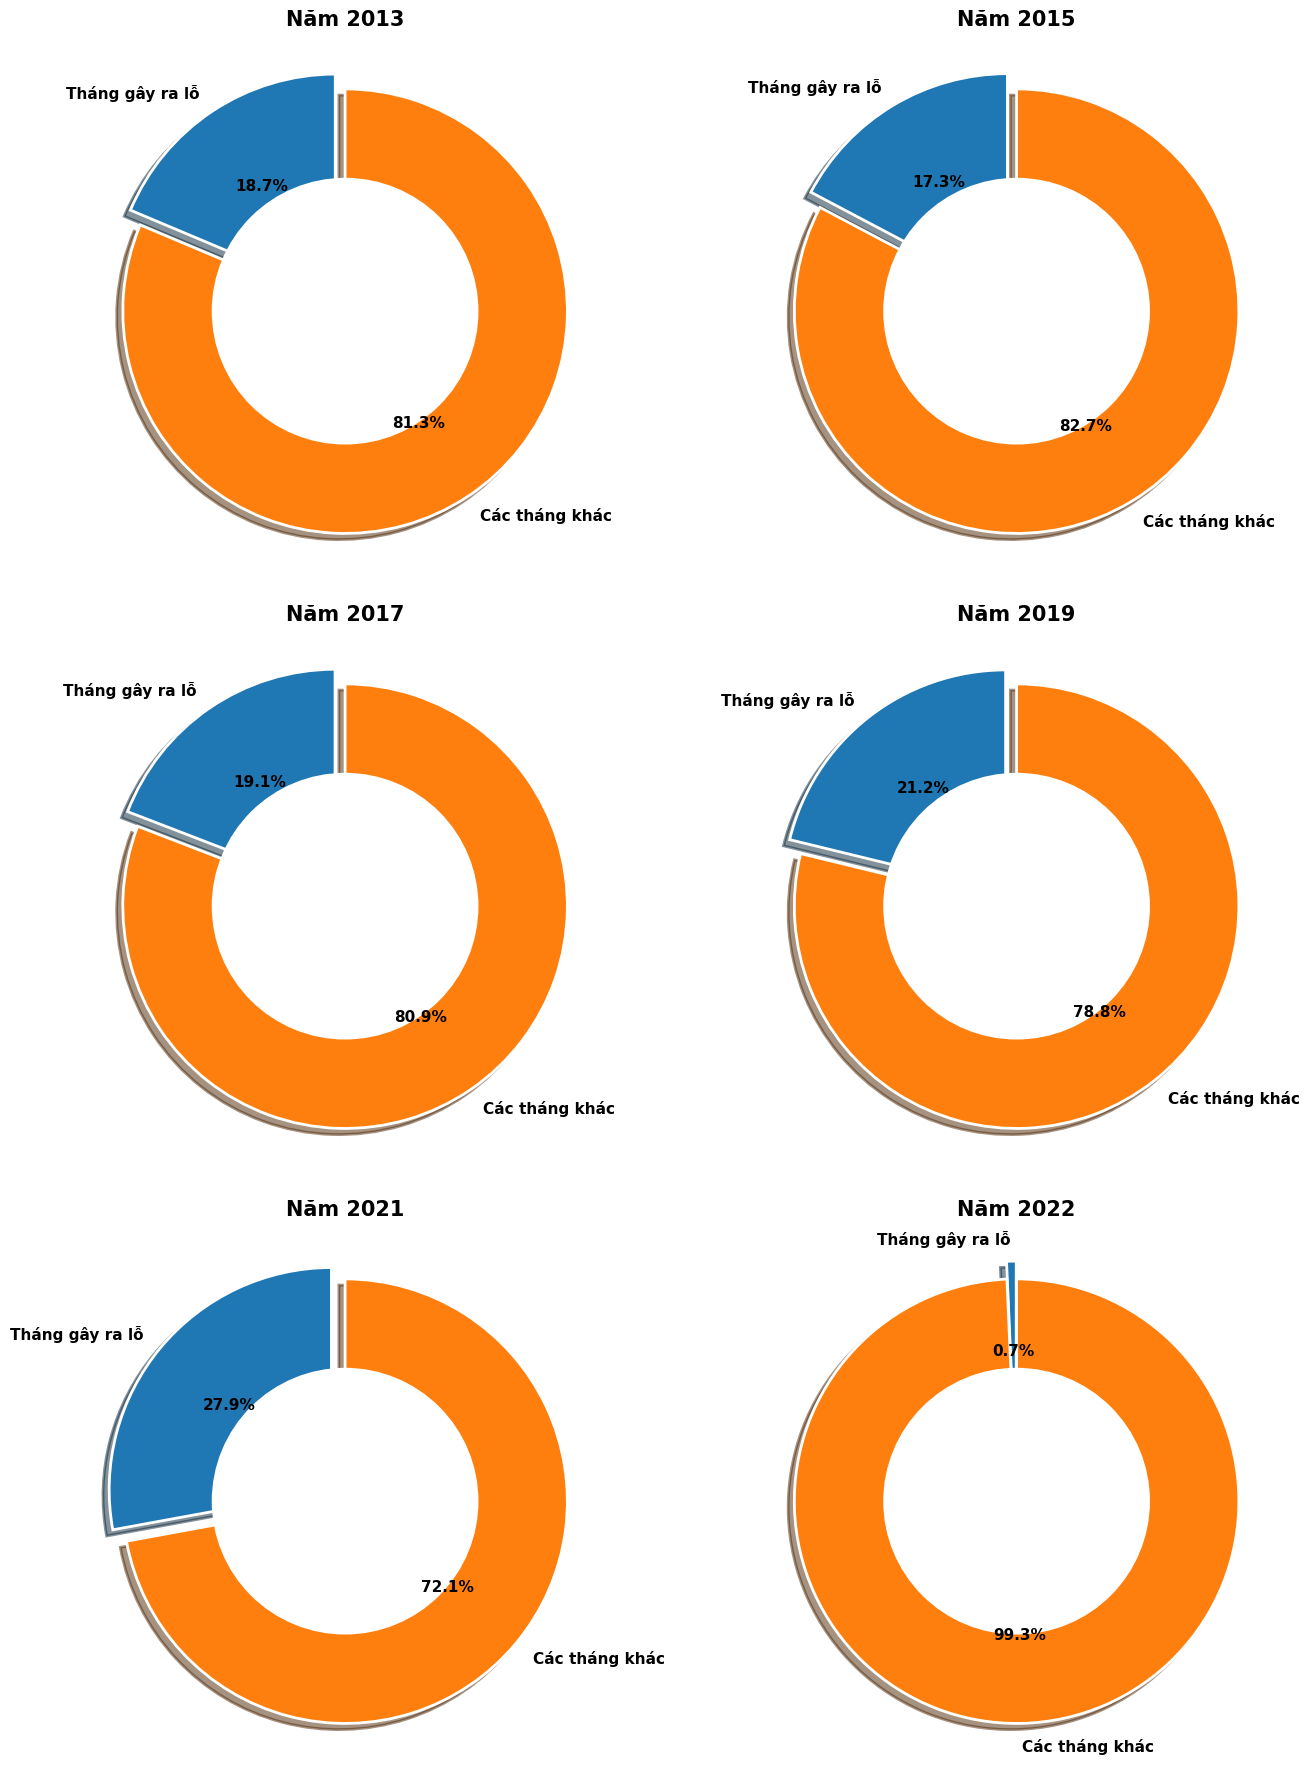

In [23]:
import matplotlib.pyplot as plt
import math

n = len(dateFocus)

# 2 biểu đồ mỗi hàng
cols = 2
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 6))

# nếu chỉ có 1 hàng thì chuyển thành list cho dễ xử lý
axes = axes.flatten()

for idx, (_, row) in enumerate(dateFocus.iterrows()):

    values = [
        row["ReFocusProfit"],
        row["Profit"] - row["ReFocusProfit"]
    ]

    labels = ["Tháng gây ra lỗ", "Các tháng khác"]

    explode = (0.08, 0)

    axes[idx].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        explode=explode,
        shadow=True,
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 2
        },
        textprops={
            'fontsize': 11,
            'fontweight': 'bold'
        }
    )

    # donut chart
    centre_circle = plt.Circle((0, 0), 0.60, fc='white')
    axes[idx].add_artist(centre_circle)

    axes[idx].set_title(
        f"Năm {int(row['year'])}",
        fontsize=15,
        fontweight='bold'
    )

# xóa ô thừa nếu số biểu đồ lẻ
for i in range(idx + 1, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

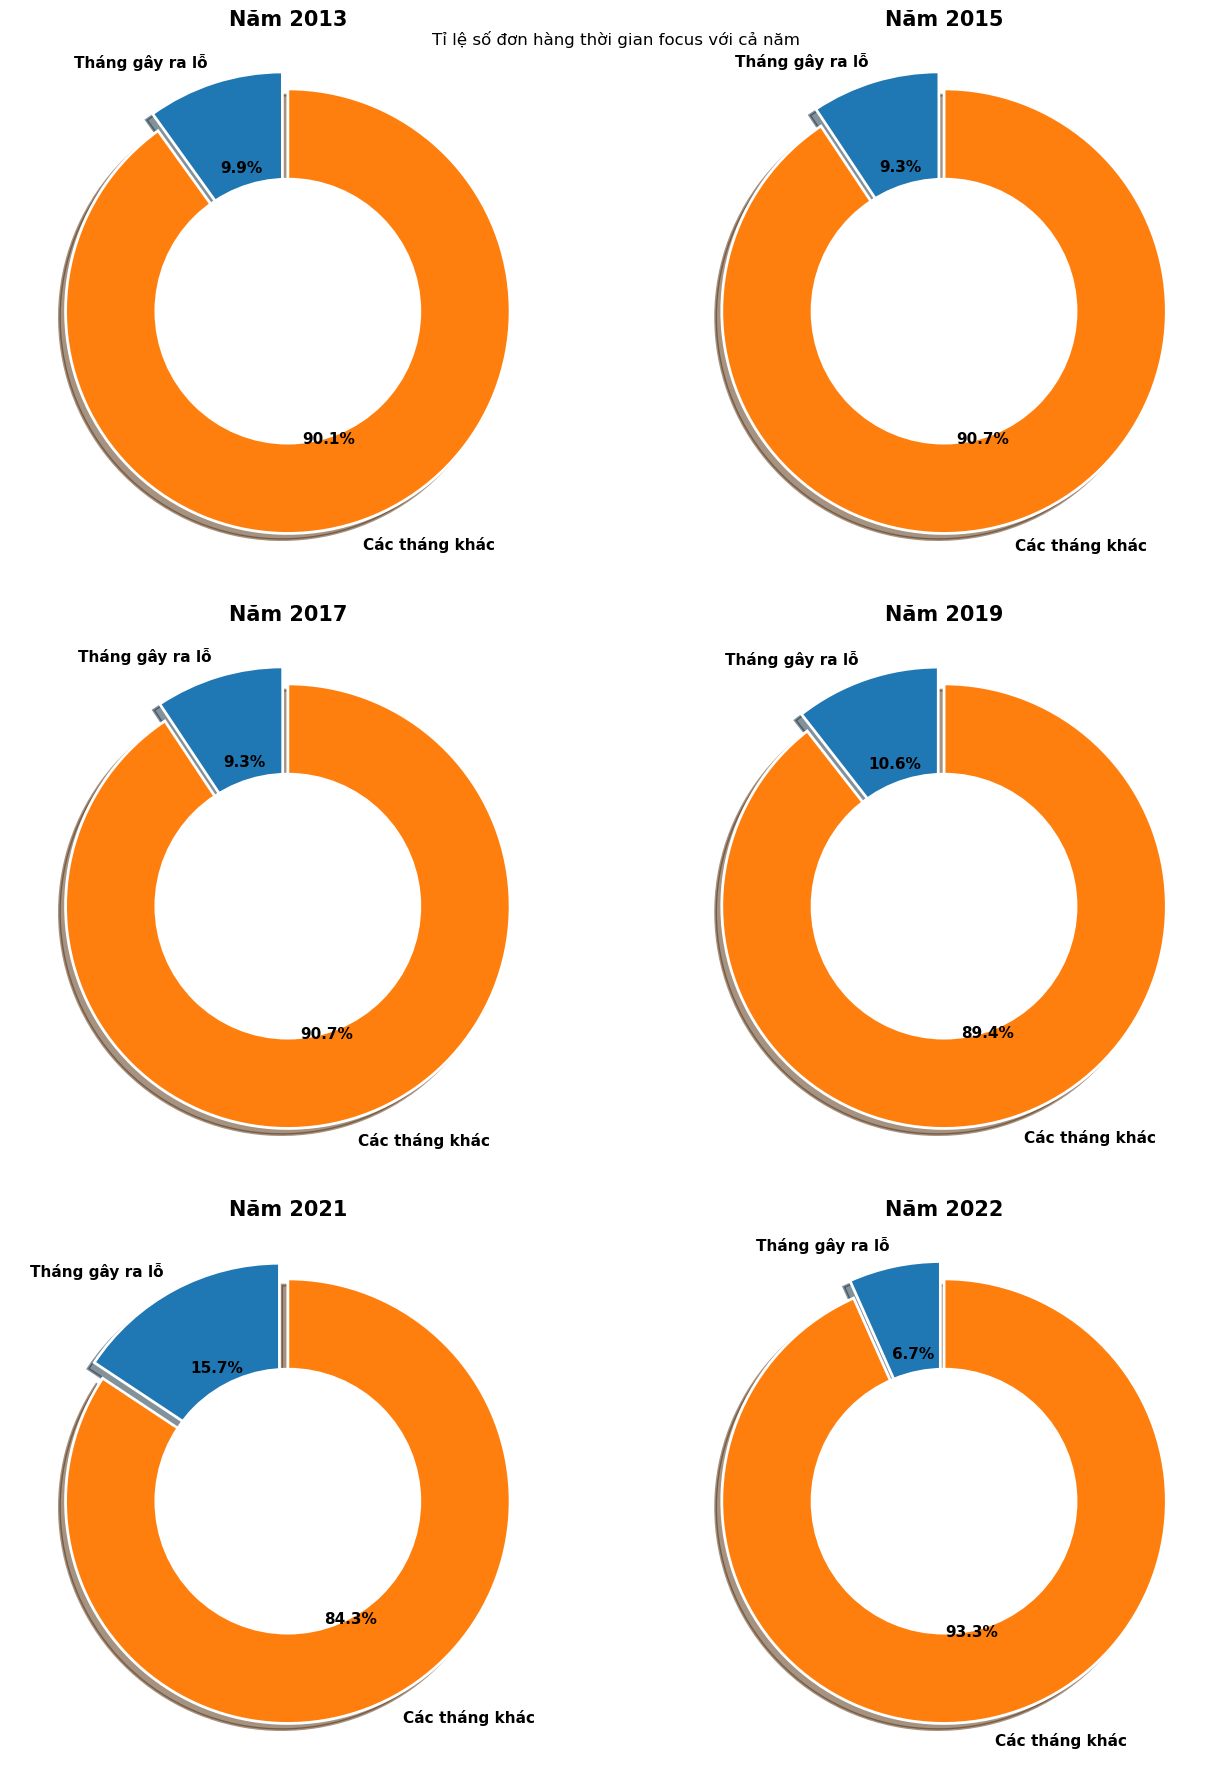

In [24]:
import matplotlib.pyplot as plt
import math

n = len(dateFocus)

# 2 biểu đồ mỗi hàng
cols = 2
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 6))

# nếu chỉ có 1 hàng thì chuyển thành list cho dễ xử lý
axes = axes.flatten()

for idx, (_, row) in enumerate(dateFocus.iterrows()):

    values = [
        row["Focuscount_order"],
        row["totalOrder"] - row["Focuscount_order"]
    ]

    labels = ["Tháng gây ra lỗ", "Các tháng khác"]

    explode = (0.08, 0)

    axes[idx].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        explode=explode,
        shadow=True,
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 2
        },
        textprops={
            'fontsize': 11,
            'fontweight': 'bold'
        }
    )

    # donut chart
    centre_circle = plt.Circle((0, 0), 0.60, fc='white')
    axes[idx].add_artist(centre_circle)

    axes[idx].set_title(
        f"Năm {int(row['year'])}",
        fontsize=15,
        fontweight='bold'
    )

# xóa ô thừa nếu số biểu đồ lẻ
for i in range(idx + 1, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.suptitle("Tỉ lệ số đơn hàng thời gian focus với cả năm")
plt.show()

In [25]:
# Các nguyên nhân có thể gây ra lỗ 
# Chương trình giảm giá
# Trả hàng
# Sản phẩm không bán được

In [26]:
dateFocus_WareHouse = profitbyyearMonth[profitbyyearMonth["Profit"] <= 0][["year","month"]]
dateFocus_WareHouse

,year,month
13,2013,8
37,2015,8
61,2017,8
85,2019,8
109,2021,8
113,2021,12
125,2022,12


In [27]:
dfWareHouse = pd.read_csv("Operational/inventory.csv")
print(dfWareHouse.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60247 entries, 0 to 60246
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   snapshot_date      60247 non-null  object 
 1   product_id         60247 non-null  int64  
 2   stock_on_hand      60247 non-null  int64  
 3   units_received     60247 non-null  int64  
 4   units_sold         60247 non-null  int64  
 5   stockout_days      60247 non-null  int64  
 6   days_of_supply     60247 non-null  float64
 7   fill_rate          60247 non-null  float64
 8   stockout_flag      60247 non-null  int64  
 9   overstock_flag     60247 non-null  int64  
 10  reorder_flag       60247 non-null  int64  
 11  sell_through_rate  60247 non-null  float64
 12  product_name       60247 non-null  object 
 13  category           60247 non-null  object 
 14  segment            60247 non-null  object 
 15  year               60247 non-null  int64  
 16  month              602

In [28]:
(dfWareHouse.head(5))

,snapshot_date,product_id,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,stockout_flag,overstock_flag,reorder_flag,sell_through_rate,product_name,category,segment,year,month
0,2022-10-31,1,3,1,1,2,90.0,0.9333,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,10
1,2022-11-30,1,3,1,1,1,90.0,0.9667,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,11
2,2022-12-31,1,3,1,1,1,90.0,0.9667,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,12
3,2016-04-30,3,35,13,11,2,95.5,0.9333,1,1,0,0.2391,DragonWear MA-03,Casual,All-weather,2016,4
4,2016-05-31,3,36,11,10,1,108.0,0.9667,1,1,0,0.2174,DragonWear MA-03,Casual,All-weather,2016,5


In [29]:
dateFocus_WareHouse = pd.merge(dateFocus_WareHouse, dfWareHouse[["product_id","units_received", "units_sold","year","month"]], on = ["year","month"], how = "inner")

In [30]:
dateFocus_WareHouse

,year,month,product_id,units_received,units_sold
0,2013,8,4,14,13
1,2013,8,31,8,7
2,2013,8,36,18,16
3,2013,8,76,8,7
4,2013,8,86,7,6
...,...,...,...,...,...
3416,2022,12,2396,5,4
3417,2022,12,2402,1,1
3418,2022,12,2403,21,18
3419,2022,12,2405,1,1


In [31]:
dateFocus_WareHouse["Redundant"] = dateFocus_WareHouse["units_received"] - dateFocus_WareHouse["units_sold"]
dateFocus_WareHouse["perSold"] = dateFocus_WareHouse["units_sold"]/dateFocus_WareHouse["units_received"]
# dateFocus_WareHouse = dateFocus_WareHouse[dateFocus_WareHouse["Redundant"] > 0]
dateFocus_WareHouse.describe()

,year,month,product_id,units_received,units_sold,Redundant,perSold
count,3421.000000,3421.000000,3421.000000,3421.000000,3421.000000,3421.000000,3421.000000
mean,2018.186787,9.025431,1314.289389,18.163403,15.478515,2.684887,0.925556
std,3.078963,1.746742,679.979041,33.813246,28.040560,6.050381,0.079862
min,2013.000000,8.000000,1.000000,1.000000,1.000000,0.000000,0.771084
25%,2015.000000,8.000000,760.000000,2.000000,2.000000,0.000000,0.850000
50%,2019.000000,8.000000,1262.000000,6.000000,5.000000,1.000000,0.944444
75%,2021.000000,12.000000,1934.000000,19.000000,17.000000,3.000000,1.000000
max,2022.000000,12.000000,2412.000000,446.000000,348.000000,98.000000,1.000000


In [32]:
dfProduct =  pd.read_csv("Master/products.csv")
dateFocus_WareHouse = pd.merge(dateFocus_WareHouse, dfProduct[["product_id", "segment","cogs"]], on = ["product_id"], how = "inner")
dateFocus_WareHouse

,year,month,product_id,units_received,units_sold,Redundant,perSold,segment,cogs
0,2013,8,4,14,13,1,0.928571,All-weather,5604.032128
1,2013,8,31,8,7,1,0.875000,All-weather,7894.333681
2,2013,8,36,18,16,2,0.888889,All-weather,3526.065368
3,2013,8,76,8,7,1,0.875000,Balanced,9422.550900
4,2013,8,86,7,6,1,0.857143,Balanced,13466.250000
...,...,...,...,...,...,...,...,...,...
3416,2022,12,2396,5,4,1,0.800000,Trendy,799.015776
3417,2022,12,2402,1,1,0,1.000000,Trendy,1874.442264
3418,2022,12,2403,21,18,3,0.857143,Trendy,850.276517
3419,2022,12,2405,1,1,0,1.000000,Trendy,2906.000573


In [33]:
dateFocus_WareHouse["Loss_by_Redundant"] = round(dateFocus_WareHouse["cogs"]/100,2) * dateFocus_WareHouse["Redundant"]
dateFocus_WareHouse

,year,month,product_id,units_received,units_sold,Redundant,perSold,segment,cogs,Loss_by_Redundant
0,2013,8,4,14,13,1,0.928571,All-weather,5604.032128,56.04
1,2013,8,31,8,7,1,0.875000,All-weather,7894.333681,78.94
2,2013,8,36,18,16,2,0.888889,All-weather,3526.065368,70.52
3,2013,8,76,8,7,1,0.875000,Balanced,9422.550900,94.23
4,2013,8,86,7,6,1,0.857143,Balanced,13466.250000,134.66
...,...,...,...,...,...,...,...,...,...,...
3416,2022,12,2396,5,4,1,0.800000,Trendy,799.015776,7.99
3417,2022,12,2402,1,1,0,1.000000,Trendy,1874.442264,0.00
3418,2022,12,2403,21,18,3,0.857143,Trendy,850.276517,25.50
3419,2022,12,2405,1,1,0,1.000000,Trendy,2906.000573,0.00


In [34]:
dateFocus_WareHouse = dateFocus_WareHouse.groupby(["year"])["Loss_by_Redundant"].sum().reset_index().sort_values(by = ["year"])
dateFocus_WareHouse

,year,Loss_by_Redundant
0,2013,87117.68
1,2015,85479.72
2,2017,91940.44
3,2019,54405.81
4,2021,72967.16
5,2022,21822.92


In [35]:
dfOrdeDiscount =  pd.merge(dfOrder[["order_id", "year", "month"]], dfOrder_item[["order_id","discount_amount"]], on ="order_id", how = "inner")


In [36]:
dfOrdeDiscount = dfOrdeDiscount[dfOrdeDiscount["discount_amount"] > 0]
dfOrdeDiscount

,order_id,year,month,discount_amount
41316,46253,2013,2,1127.74
41317,46254,2013,2,1312.20
41319,46257,2013,2,269.54
41320,46257,2013,2,183.50
41321,46258,2013,2,544.24
...,...,...,...,...
714648,834325,2022,12,2284.89
714649,834326,2022,12,5788.22
714650,834329,2022,12,2220.70
714651,834333,2022,12,23276.04


In [37]:
dateNeedForcus = profitbyyearMonth[profitbyyearMonth["Profit"] <= 0][["year","month"]]

In [38]:
dfOrdeDiscount = pd.merge(dfOrdeDiscount[["year","month","discount_amount"]], dateNeedForcus, on = ["year","month"], how = "inner")
dfOrdeDiscount["discount_amount"] = dfOrdeDiscount["discount_amount"]/100
dfOrdeDiscount = dfOrdeDiscount.groupby(["year"])["discount_amount"].sum().reset_index().sort_values(by = ["year"])
dfOrdeDiscount

,year,discount_amount
0,2013,11593.4611
1,2015,12209.9098
2,2017,11230.5434
3,2019,7831.5276
4,2021,106266.6929
5,2022,103657.7639


In [39]:
dfReturn = pd.read_csv("Transaction/returns.csv")
dateFocusReturn  = dfReturn.copy()

In [40]:
dateFocusReturn = dateFocusReturn[["return_date", "refund_amount"]]
dateFocusReturn["return_date"] = pd.to_datetime(dateFocusReturn["return_date"])
dateFocusReturn["year"] = dateFocusReturn["return_date"].dt.year
dateFocusReturn["month"] = dateFocusReturn["return_date"].dt.month
dateFocusReturn

,return_date,refund_amount,year,month
0,2012-07-25,52458.01,2012,7
1,2012-07-16,5141.37,2012,7
2,2012-07-16,5315.95,2012,7
3,2012-07-11,6493.75,2012,7
4,2012-07-25,1740.76,2012,7
...,...,...,...,...
39934,2022-12-27,24741.62,2022,12
39935,2022-12-30,560.50,2022,12
39936,2022-12-31,10002.55,2022,12
39937,2022-12-28,815.57,2022,12


In [41]:
dateFocusReturn = pd.merge(dateFocusReturn[["year","month","refund_amount"]], dateNeedForcus, on = ["year","month"], how = "inner")
dateFocusReturn["refund_amount"] = round(dateFocusReturn["refund_amount"]/100, 2)
dateFocusReturn = dateFocusReturn.groupby(["year"])["refund_amount"].sum().reset_index().sort_values(by = ["year"])
dateFocusReturn

,year,refund_amount
0,2013,47842.51
1,2015,49661.84
2,2017,53316.09
3,2019,24904.68
4,2021,41130.90
5,2022,15086.06


In [42]:
dateFocus_WareHouse

,year,Loss_by_Redundant
0,2013,87117.68
1,2015,85479.72
2,2017,91940.44
3,2019,54405.81
4,2021,72967.16
5,2022,21822.92


In [43]:
dfOrdeDiscount

,year,discount_amount
0,2013,11593.4611
1,2015,12209.9098
2,2017,11230.5434
3,2019,7831.5276
4,2021,106266.6929
5,2022,103657.7639


In [44]:
dateFocus

,year,FocusProfit,Focuscount_order,totalOrder,Profit,ReFocusProfit
0,2013,-356759.3504,7630,76849,1.911893e+06,356759.3504
1,2015,-387716.2248,7717,82622,2.244920e+06,387716.2248
2,2017,-415121.1125,7091,76010,2.167785e+06,415121.1125
3,2019,-279003.4902,4391,41601,1.315986e+06,279003.4902
4,2021,-284148.8645,5411,34525,1.019097e+06,284148.8645
5,2022,-10347.3724,2400,36004,1.493287e+06,10347.3724


In [45]:
(87117.68 + 11593.4611 + 47842.5) / 356759.35 *100

41.079131100558406

In [56]:
dfLoss = pd.merge(dateFocus[["year", "ReFocusProfit"]], dfOrdeDiscount, on = 'year', how = "inner")
dfLoss = pd.merge(dateFocus_WareHouse, dfLoss, on = 'year', how = "inner")
dfLoss = pd.merge(dateFocusReturn, dfLoss, on = 'year', how = "inner")

In [58]:
dfLoss

,year,refund_amount,Loss_by_Redundant,ReFocusProfit,discount_amount
0,2013,47842.51,87117.68,356759.3504,11593.4611
1,2015,49661.84,85479.72,387716.2248,12209.9098
2,2017,53316.09,91940.44,415121.1125,11230.5434
3,2019,24904.68,54405.81,279003.4902,7831.5276
4,2021,41130.90,72967.16,284148.8645,106266.6929
5,2022,15086.06,21822.92,10347.3724,103657.7639


In [72]:
dfLoss["FinalLoss"] = dfLoss["ReFocusProfit"] - (dfLoss["Loss_by_Redundant"] + dfLoss["refund_amount"] + dfLoss["discount_amount"])
dfLoss["PerLoss"] =  (dfLoss["Loss_by_Redundant"] + dfLoss["refund_amount"] + dfLoss["discount_amount"]) / dfLoss["ReFocusProfit"]

In [74]:
dfLoss

,year,refund_amount,Loss_by_Redundant,ReFocusProfit,discount_amount,FinalLoss,PerLoss
0,2013,47842.51,87117.68,356759.3504,11593.4611,210205.6993,0.410791
1,2015,49661.84,85479.72,387716.2248,12209.9098,240364.7550,0.380050
2,2017,53316.09,91940.44,415121.1125,11230.5434,258634.0391,0.376967
3,2019,24904.68,54405.81,279003.4902,7831.5276,191861.4726,0.312333
4,2021,41130.90,72967.16,284148.8645,106266.6929,63784.1116,0.775526
5,2022,15086.06,21822.92,10347.3724,103657.7639,-130219.3715,13.584777


In [ ]:
# profitbyyearMonth[profitbyyearMonth["Profit"] <= 0][["year","month"]]

In [ ]:
dfSaless = dfSale[dfSale["COGS"] >= dfSale["Revenue"]].groupby(["year","month"])["COGS"].sum().reset_index().sort_values(by = ["year","month"])

In [ ]:
dfSaless = pd.merge(dfSaless, dateNeedForcus, on = ["year","month"], how = "inner")

In [ ]:
dfSaless = dfSaless.groupby(["year"])["COGS"].sum().reset_index().sort_values(by = ["year"])

In [ ]:
dfSaless

In [ ]:
# dfLoss = pd.merge(dfSaless, dfOrdeDiscount, on = 'year', how = "inner")
# dfLoss = pd.merge(dateFocus_WareHouse, dfLoss, on = 'year', how = "inner")
# dfLoss = pd.merge(dateFocusReturn, dfLoss, on = 'year', how = "inner")

In [ ]:
á

## Chương trình khuyến mại

In [ ]:
dfPromotions = pd.read_csv("Master/promotions.csv")
dfPromotions.info()

In [ ]:
dfPromotions["start_date"] = pd.to_datetime(dfPromotions["start_date"])
dfPromotions["end_date"] = pd.to_datetime(dfPromotions["end_date"])
dfPromotions['year'] = dfPromotions['start_date'].dt.year
dfPromotions['month'] = dfPromotions['start_date'].dt.month
dfPromotions['duration'] = (dfPromotions['end_date'] - dfPromotions['start_date']).dt.days
dfPromotions["yearMonth"] = dfPromotions["start_date"].dt.strftime("%Y-%m")


In [ ]:
dfPromotions.head()

In [ ]:
dfOrderFull = pd.merge(dfOrder, dfOrder_item, on='order_id', how='inner')

In [ ]:
dfOrderFull.head()

In [ ]:
dfProduct = pd.read_csv("Master/products.csv")

In [ ]:
# Số tiền để dành cho khuyến mãi
dfDisCountAmount_Year =  dfOrderFull.groupby(["year"])["discount_amount"].sum().reset_index().sort_values(by = ['year'])
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    dfDisCountAmount_Year["year"],
    dfDisCountAmount_Year["discount_amount"],
    
)
ax.set_title("BIỂU ĐỒ CỘT SỐ TIỀN DÀNH ĐỂ GIẢM GIÁ QUA CÁC NĂM")
ax.set_ylabel('TIỀN')
ax.set_xlabel('NĂM', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(2012,2023))
plt.show()

In [ ]:
dfDisCountAmount_year_Month =  dfOrderFull.groupby(["year",'month'])["discount_amount"].sum().reset_index().sort_values(by = ['year', 'month'])
dfDisCountAmount_year_Month['date'] = pd.to_datetime(dfDisCountAmount_year_Month[['year', 'month']].assign(DAY=1))
dfDisCountAmount_year_Month = dfDisCountAmount_year_Month.sort_values('date')


x0 = dfDisCountAmount_year_Month['date'].map(pd.Timestamp.toordinal)
y0 = dfDisCountAmount_year_Month['discount_amount']


coeffs0 = np.polyfit(x0, y0, 1)
trend0 = np.poly1d(coeffs0)
trend_values0 = trend0(x0)


plt.figure(figsize=(14, 6))


# plt.subplot(3,2,1)
plt.plot(
    dfDisCountAmount_year_Month['date'],
    dfDisCountAmount_year_Month['discount_amount'],
    label='discount_amount',
    marker='o',
    color='#DD8452')


plt.plot(
    dfDisCountAmount_year_Month['date'],
    trend_values0,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs0[0]:.6f}'
)


plt.title('SỐ TIỀN CHI TIÊU CHO CÁC VOURCHE GIẢM GIÁ(2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.show()

In [ ]:
dfDisCountAmount_year_Month =  dfOrderFull.groupby(["year",'month'])["discount_amount"].sum().reset_index().sort_values(by = ['year', 'month'])

In [ ]:
dfDisCountAmount_year_Month.sort_values(by = "discount_amount", ascending = False)[:20]

In [ ]:
min_year = dfDisCountAmount_year_Month["year"].min()
max_year = dfDisCountAmount_year_Month["year"].max()

sizeOfYear = (dfDisCountAmount_year_Month["year"].unique())

numCol =  2
numRow =  int(round(len(sizeOfYear)/2,0))
indexPlot = 1
plt.figure(figsize=(20,15))
for year in range(min_year, max_year + 1):
    plt.subplot(numRow, numCol, indexPlot)
    
    df_year = dfDisCountAmount_year_Month[
        dfDisCountAmount_year_Month["year"] == year
    ]
    
    plt.plot(
        df_year["month"],
        df_year["discount_amount"],
        label=f"{year}",
        marker = 'o'
    )
    plt.legend()
    plt.xticks(range(1,13))  
    plt.grid(ls = "--")
    indexPlot += 1
plt.show()

# Quản lý kho

In [ ]:
dfWareHouse  = pd.read_csv("Operational/inventory.csv")
df_plot = dfWareHouse.copy()
dfWareHouse.info()

In [ ]:
dfWareHouse.describe()

In [ ]:
monthly_trend = dfWareHouse.groupby(['year', 'month'])[['units_sold', 'units_received']].sum().reset_index()
monthly_trend.info()

## Tổng quan về kho

In [ ]:
monthly_trend['per'] = (monthly_trend['units_sold']/monthly_trend['units_received'])

In [ ]:
monthly_trend['date'] = pd.to_datetime(monthly_trend[['year', 'month']].assign(DAY=1))
monthly_trend = monthly_trend.sort_values('date')

# Tùy chỉnh Matplotlib line chart
plt.figure(figsize=(14, 6))
plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='Units Sold', marker='o', color='#DD8452')
plt.plot(monthly_trend['date'], monthly_trend['units_received'], label='Units Received', marker='s', color='#4C72B0', alpha=0.7)

plt.title('Xu hướng Nhập - Xuất hàng theo thời gian (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
x = monthly_trend['date'].map(pd.Timestamp.toordinal)
y1 = monthly_trend['units_sold']


coeffs1 = np.polyfit(x, y1, 1)
trend1 = np.poly1d(coeffs1)
trend_values1 = trend1(x)


plt.figure(figsize=(14, 10))


plt.subplot(3,2,1)
plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values1,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs1[0]:.6f}'
)


plt.title('HÀNG NHẬP(2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)



plt.subplot(3,2,2)
y2 = monthly_trend['units_received']


coeffs2 = np.polyfit(x, y2, 1)
trend2 = np.poly1d(coeffs2)
trend_values2 = trend2(x)

plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values2,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs2[0]:.6f}'
)
plt.title('HÀNG BÁN (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.subplot(3,2,3)
y3 = monthly_trend['per']


coeffs3 = np.polyfit(x, y3, 1)
trend3 = np.poly1d(coeffs3)
trend_values3 = trend3(x)

plt.plot(monthly_trend['date'], monthly_trend['per'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values3,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs3[0]:.6f}'
)

plt.title('TỈ LỆ TIÊU THỤ GIỮA HÀNG NHẬP - BÁN (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Tỉ lệ')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

In [ ]:
monthly_trend
pd.pivot_table(monthly_trend, values='per', index=['year'], columns=['month'], aggfunc='sum').fillna(0)

In [ ]:
import seaborn as sns
plt.figure(figsize=(10, 8))

# Lọc các cột số (numeric) cần phân tích
corr_cols = ['stock_on_hand', 'units_received', 'units_sold', 'stockout_days', 'days_of_supply', 'fill_rate', 'sell_through_rate','stockout_flag', 'overstock_flag']
corr = dfWareHouse[corr_cols].corr()

# Tùy chỉnh Seaborn heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Biểu đồ Heatmap Tương quan (Correlation) các chỉ số Inventory')
plt.tight_layout()
plt.show()

**Phân tích này giúp xác định cách các chỉ số chuỗi cung ứng tác động qua lại lẫn nhau:**
- Tỷ lệ Bán ra (Sell-through rate): Chỉ số này có tương quan âm (-0.37) với stock_on_hand và days_of_supply. Nghĩa là khi lượng hàng tồn hoặc số ngày lưu kho tăng lên, tốc độ bán ra thực tế lại có xu hướng giảm. Đây là một điểm nghẽn (bottleneck) đáng chú ý, cho thấy dấu hiệu đọng vốn do overstock và là một chủ đề rất tốt để đưa ra thảo luận trong các buổi brainstorming sắp tới cùng team.

## Tình trạng thiếu hàng

In [ ]:
# Tình hình thiếu hàng ở từng danh mục sản phẩm
dfstockout_flag = dfWareHouse.groupby(["year","category"])["stockout_flag"].mean().reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfstockout_flag, values='stockout_flag', index=['category'], columns=['year'], aggfunc='sum')

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Tần suất xảy ra tình trạng hết hàng', fontsize=13)

ax[0,0].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Streetwear"]["stockout_flag"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "GenZ"]["stockout_flag"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Casual"]["stockout_flag"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Outdoor"]["stockout_flag"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

In [ ]:
plt.rcParams['figure.figsize'] = (18, 4)
pd.pivot_table(dfstockout_flag, values='stockout_flag', index=['year'], columns=['category'], aggfunc='sum').plot(kind = 'bar', stacked = False)
plt.xticks(rotation = 0)
plt.grid(ls = "--")
plt.legend(title='Category', loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

In [ ]:
# Số ngày hết hàng trong tháng của mỗi sản phẩm
dfstockout_days = dfWareHouse.groupby(["year","category"])["stockout_days"].mean().sort_values(ascending=False).reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfstockout_days, values='stockout_days', index=['category'], columns=['year'], aggfunc='sum')

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Số ngày hết hàng trung bình theo năm và danh mục', fontsize=13)

ax[0,0].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Streetwear"]["stockout_days"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "GenZ"]["stockout_days"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Casual"]["stockout_days"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Outdoor"]["stockout_days"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

## Thừa hàng

In [ ]:
# Hàng hóa gặp tình trạng vượt quá mức cần thiết
dfMeanoverstock_flag = dfWareHouse.groupby(["year","category"])["overstock_flag"].mean().reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfMeanoverstock_flag, values='overstock_flag', index=['category'], columns=['year'], aggfunc='sum')

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Tần suất xảy ra tình trạng thừa hàng theo các năm', fontsize=13)

ax[0,0].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Streetwear"]["overstock_flag"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "GenZ"]["overstock_flag"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Casual"]["overstock_flag"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Outdoor"]["overstock_flag"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

In [ ]:
plt.rcParams['figure.figsize'] = (18, 4)
pd.pivot_table(dfMeanoverstock_flag, values='overstock_flag', index=['year'], columns=['category'], aggfunc='sum').plot(kind = 'bar', stacked = False)
plt.xticks(rotation = 0)
plt.grid(ls = "--")
plt.legend(title='Category', loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

In [ ]:
# Loại hàng cần tái đặt hàng sớm nhiều nhất
dfCategory_Reorder_Flag = dfWareHouse.groupby(["year","category"])["reorder_flag"].sum().sort_values(ascending=False).reset_index()
pd.pivot_table(dfCategory_Reorder_Flag, values='reorder_flag', index=['category'], columns=['year'], aggfunc='sum')

# SỐ LƯỢNG ĐƠN HÀNG + TRẢ HÀNG

In [ ]:
dfOrder_item = pd.read_csv("Transaction/order_items.csv")
dfOrder = pd.read_csv("Transaction/orders.csv")
dfOrder_item.info()

In [ ]:
dfOrder.info()

In [ ]:
# Số lượng đơn hàng
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder["yearMonth"] = dfOrder["order_date"].dt.strftime("%Y-%m")
dfOrder["year"] = dfOrder["order_date"].dt.year
dfOrder["month"] = dfOrder["order_date"].dt.month
dfOrder.head()

In [ ]:
dfDisCountOrderID =  dfOrderFull.groupby(["year",'month'])["order_id"].count().reset_index().sort_values(by = ['year', 'month'])
dfDisCountOrderID['date'] = pd.to_datetime(dfDisCountOrderID[['year', 'month']].assign(DAY=1))
dfDisCountOrderID = dfDisCountOrderID.sort_values('date')


x_count_orderID = dfDisCountOrderID['date'].map(pd.Timestamp.toordinal)
y_count_orderID = dfDisCountOrderID['order_id']


coeffs_count_orderID = np.polyfit(x_count_orderID, y_count_orderID, 1)
trend_count_orderID = np.poly1d(coeffs_count_orderID)
trend_values_count_orderID = trend_count_orderID(x_count_orderID)


plt.figure(figsize=(14, 6))


# plt.subplot(3,2,1)
plt.plot(
    dfDisCountOrderID['date'],
    dfDisCountOrderID['order_id'],
    label='order_id',
    marker='o',
    color='#DD8452')


plt.plot(
    dfDisCountOrderID['date'],
    trend_values_count_orderID,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs_count_orderID[0]:.6f}'
)


plt.title('SỐ LƯỢNG ĐƠN HÀNG(2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.show()

In [ ]:
dfPayment = pd.read_csv("Transaction/payments.csv")
df = pd.merge(dfPayment, dfOrder, on='order_id', how='inner')
# Gom dữ liệu theo từng năm
years = sorted(df["year"].unique())
data = [df[df["year"] == y]["payment_value"] for y in years]

plt.figure(figsize=(10,6))

plt.boxplot(data, labels=years,showmeans=True)

plt.title("Phân bổ giá trị đơn hàng theo năm")
plt.xlabel("NĂM")
plt.ylabel("GIÁ TRỊ MỖI ĐƠN HÀNG")

plt.show()

1. Xu hướng chung: giá trị đơn hàng đang tăng theo thời gian Median (đường màu cam trong box) tăng đều từ 2012 → 2022 Điều này cho thấy: → Khách hàng đang chi tiêu nhiều hơn qua từng năm → Hoặc giá sản phẩm / chiến lược pricing đã thay đổi
2. Độ phân tán ngày càng lớn (variance tăng) Box (IQR) và whisker ngày càng cao hơn theo năm Nghĩa là: → Hành vi khách hàng không còn đồng đều → Có sự phân hóa rõ: Nhóm mua ít Nhóm mua rất nhiều
👉 Đây là dấu hiệu của:

mở rộng tệp khách hàng hoặc thêm nhiều phân khúc sản phẩm (giá rẻ → cao cấp)

3. Outliers cực nhiều và tăng mạnh Các chấm đen phía trên rất dày, đặc biệt từ 2017 trở đi Có những đơn hàng rất lớn (200k–300k+)
→ Điều này thường là:

đơn bulk / B2B hoặc campaign lớn / khách VIP

👉 Nhưng cũng cần cảnh giác:

Có thể là data skew → mean sẽ bị kéo lệch rất mạnh

4. Median tăng nhưng không quá đột biến Tăng đều, không có năm nào “nhảy vọt” quá lớn → Tăng trưởng khá ổn định, không phải kiểu spike bất thường
5. Insight quan trọng (điểm ăn tiền nếu đưa vào portfolio) Doanh thu tăng có thể không đến từ toàn bộ khách hàng → mà đến từ một nhóm nhỏ khách chi tiêu lớn (outliers) Nếu bạn chỉ nhìn mean → sẽ bị “ảo tưởng tăng trưởng” Boxplot giúp thấy: → phần lớn khách vẫn chi tiêu ở mức trung bình vừa phải

In [ ]:
dfPayment_mer_Order = pd.merge(dfPayment, dfOrder, on='order_id', how='inner')
trungBinhDoanhThuMoiDonHang = dfPayment_mer_Order.groupby("year")["payment_value"].mean().reset_index().sort_values(by = 'year')
trungBinhDoanhThuMoiDonHang
plt.bar(
    trungBinhDoanhThuMoiDonHang["year"],
    trungBinhDoanhThuMoiDonHang["payment_value"],
)
plt.title("TRUNG BÌNH DOANH THU TỪ MỖI ĐƠN HÀNG(2012-2022)")
plt.xlabel("NĂM")
plt.ylabel("GIÁ TRỊ MỖI ĐƠN HÀNG")
plt.xticks(range(2012,2022+1))  
plt.grid(ls = '--')
plt.show()

In [ ]:
dfReturn  = pd.read_csv("Transaction/returns.csv")
dfReturn.info()

In [ ]:
# dfReturn["return_date"] = pd.to_datetime(dfReturn["return_date"])
# dfReturn["year"] = dfReturn["return_date"].dt.year
# dfReturn["month"] = dfReturn["return_date"].dt.month
dfReturn.head()

In [ ]:
dfReturn_mer_dfOrder = pd.merge(dfReturn, dfOrder, on= ["order_id"], how = "inner")
dfReturn_mer_dfOrder.head(3)

In [ ]:
totalOrderReturnByYear = dfReturn_mer_dfOrder.groupby(["year",'month'])["order_id"].nunique().reset_index().sort_values(by = ['year', 'month']).rename(columns={"order_id": "count_order_return"})
totalOrderByYear = dfOrder.groupby(["year",'month'])["order_id"].nunique().reset_index().sort_values(by = ['year', 'month']).rename(columns={"order_id": "count_order"})

In [ ]:
perOrderReturnByYear =  pd.merge(totalOrderReturnByYear, totalOrderByYear, on= ["year", "month"], how = "inner")

In [ ]:
perOrderReturnByYear = perOrderReturnByYear.groupby(["year"])[["count_order_return","count_order"]].sum().reset_index()

In [ ]:
perOrderReturnByYear['per'] = perOrderReturnByYear['count_order_return']/perOrderReturnByYear['count_order']
perOrderReturnByYear.head(3)

In [ ]:
# perOrderReturnByYear.groupby('year')['per'].mean().reset_index()

In [ ]:
# perOrderReturnByYear['date'] = pd.to_datetime(perOrderReturnByYear[['year', 'month']].assign(DAY=1))
perOrderReturnByYear = perOrderReturnByYear.sort_values('year')

# perOrderReturnByYear = perOrderReturnByYear.groupby(["year"])[["per"]].mean().reset_index()

# x_countOrderReturn = perOrderReturnByYear['date'].map(pd.Timestamp.toordinal)
x_countOrderReturn = perOrderReturnByYear['year']
y_countOrderReturn = perOrderReturnByYear['per']

coeffs_countOrderReturn = np.polyfit(x_countOrderReturn, y_countOrderReturn, 1)
trend_countOrderReturn = np.poly1d(coeffs_countOrderReturn)
trend_values_countOrderReturn = trend_countOrderReturn(x_countOrderReturn)


plt.figure(figsize=(14, 6))


# plt.subplot(3,2,1)
plt.plot(
    perOrderReturnByYear['year'],
    perOrderReturnByYear['per'],
    label='Số lượng đơn hàng được trả lại',
    marker='o',
    color='#DD8452')


plt.plot(
    perOrderReturnByYear['year'],
    trend_values_countOrderReturn,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs_countOrderReturn[0]:.6f}'
)


plt.title('SỐ LƯỢNG ĐƠN HÀNG DÍNH BỊ TRẢ HÀNG(2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.xticks(range(min(perOrderReturnByYear['year']),max(perOrderReturnByYear['year'])+1))  
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# totalItemInOrder = dfOrderFull.groupby(["year","month","order_id"])["product_id"].count().reset_index().rename(columns={"product_id": "count_item_order"})
# totalItemReturnInOrder = dfReturn.groupby(["order_id"])["product_id"].count().reset_index().rename(columns={"product_id": "count_item_return"})
# perItemReturnInOrder = pd.merge(totalItemInOrder, totalItemReturnInOrder, on = 'order_id', how = 'left').fillna(0)

In [ ]:
# perItemReturnInOrder['per'] = perItemReturnInOrder["count_item_return"] / perItemReturnInOrder["count_item_order"]*100

In [ ]:
# perItemReturnInOrder = perItemReturnInOrder.groupby(["year","month"])["per"].mean().reset_index()


In [ ]:
# perItemReturnInOrder['date'] = pd.to_datetime(perItemReturnInOrder[['year', 'month']].assign(DAY=1))
# perItemReturnInOrder = perItemReturnInOrder.sort_values('date')


# x_perItemReturnInOrder = perItemReturnInOrder['date'].map(pd.Timestamp.toordinal)
# y_perItemReturnInOrder = perItemReturnInOrder['per']


# coeffs_perItemReturnInOrder = np.polyfit(x_perItemReturnInOrder, y_perItemReturnInOrder, 1)
# trend_perItemReturnInOrder = np.poly1d(coeffs_perItemReturnInOrder)
# trend_values_perItemReturnInOrder = trend_perItemReturnInOrder(x_perItemReturnInOrder)


# plt.figure(figsize=(14, 6))


# # plt.subplot(3,2,1)
# plt.plot(
#     perItemReturnInOrder['date'],
#     perItemReturnInOrder['per'],
#     label='Số lượng đơn hàng được trả lại',
#     marker='o',
#     color='#DD8452')


# plt.plot(
#     perItemReturnInOrder['date'],
#     trend_values_perItemReturnInOrder,
#     linestyle='--',
#     linewidth=2,
#     label=f'Trend slope: {coeffs_perItemReturnInOrder[0]:.6f}'
# )


# plt.title('SỐ LƯỢNG ĐƠN HÀNG(2012 - 2022)')
# plt.xlabel('Thời gian')
# plt.ylabel('Số lượng')
# plt.legend()
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.show()

In [ ]:
dfReturn_mer_dfOrder["year"]

In [ ]:
dfReturn_mer_dfOrder

In [ ]:
plt.figure(figsize=(15,6))
dfrefund_amount_sum = dfReturn_mer_dfOrder.groupby('year')['refund_amount'].sum().reset_index().sort_values('year')

plt.subplot(1,2,1)
plt.plot(
    dfrefund_amount_sum['year'],
    dfrefund_amount_sum['refund_amount'],
    marker = 'o'
)

plt.title("TỔNG THẤT THOÁT TỪ VIỆC CÁC ĐƠN HÀNG BỊ HOÀN LẠI")
plt.xlabel("NĂM")
plt.ylabel("GIÁ TRỊ MỖI ĐƠN HÀNG")
plt.xticks(range(2012,2022+1))  
plt.grid(ls = '--')


plt.subplot(1,2,2)
dfrefund_amount_mean = dfReturn_mer_dfOrder.groupby('year')['refund_amount'].mean().reset_index().sort_values('year')
plt.plot(
    dfrefund_amount_mean['year'],
    dfrefund_amount_mean['refund_amount'],
    marker = 'd'
)

plt.title("TRUNG BÌNH THẤT THOÁT TỪ VIỆC CÁC ĐƠN HÀNG BỊ HOÀN LẠI")
plt.xlabel("NĂM")
plt.ylabel("GIÁ TRỊ MỖI ĐƠN HÀNG")
plt.xticks(range(2012,2022+1))  
plt.grid(ls = '--')

plt.show()

**Nhận xét**

- Tính mùa vụ cực cao sẵn sàng bán lỗ trong 1 khoảng thời gian

# SẢN PHẨM + KHUYẾN MẠI + ĐƠN HÀNG + TRẢ HÀNG + NHẬN XÉT

In [ ]:
dfProduct = pd.read_csv("Master/products.csv")

In [ ]:
dfProduct.sort_values(by = 'product_id')

## KHÁCH HÀNG VÀ VỊ TRÍ ĐỊA LÝ